# CSE366 – Artificial Intelligence | Submission 1
## "PCB-LiteX": An Explainable Lightweight Framework for Generalizable PCB Defect Detection
**Dataset, EDA and Related Work**

East West University, Department of CSE · Section 1 · Group 05
Submitted to: Dr. Tania Sultana

| # | Member | ID |
|---|--------|----|
| 1 | Saiful Islam | 2023-3-60-054 |
| 2 | Abu Bakar Siddique | 2023-3-60-058 |
| 3 | S. M. Tasmim Rahman Nayem | 2023-3-60-067 |
| 4 | Zeba Tahira | 2023-3-60-076 |
| 5 | Ramisa Jahan | 2023-3-60-287 |



| Item | Details |
|---|---|
| **Name** | PCB-Defect: An Annotated Dataset for Surface Defect Detection in Printed Circuit Boards |
| **Source link** | https://data.mendeley.com/datasets/vdj74sngvn/1 (Mendeley Data, DOI 10.17632/vdj74sngvn.1) |
| **Companion paper** | Rashid et al., *Data in Brief* 64:112296 (2025), DOI 10.1016/j.dib.2025.112296 |
| **Licence** | CC BY 4.0 (stated on the Mendeley Data page) |
| **Year** | 2025 (Version 1 published 8 Aug 2025; Data in Brief article Nov 2025) |
| **Creators / institution** | Rashid, Ullah, Isfara, Ahmed, Mian, Shalehin – Islamic University of Technology, Gazipur, Bangladesh |
| **Task type** | **Multi-class object detection** (bounding boxes + class label). It can also be turned into multi-class *patch classification* by cropping each box. |
| **Number of classes** | **6**: `missing_pad`, `mouse_bite`, `open_circuit`, `short`, `spur`, `spurious_copper` |
| **Total images** | 230 single-layer PCB scans (one unique board per image) |
| **Total annotations** | 1,704 bounding boxes (≈ 7.4 per image) in Version 1 |
| **Per-class counts (V1, from the paper)** | mouse_bite 356 · spur 296 · open_circuit 276 · missing_pad 276 · short 254 · spurious_copper 246 |
| **Image size** | Varies widely, from 800 × 600 up to 6000 × 4000 px (≈ 2.6 – 31 MP, mean ≈ 6.6 MP) – measured exactly below |
| **Channels / format** | 24-bit colour RGB (3 channels), JPEG; annotations in one COCO-style JSON (`pcb_annotations.json`) |
| **How it was made** | Defects were designed in ECAD/SVG, printed, transferred onto FR4 copper-clad boards and **physically etched** in ferric chloride, then scanned (HP ScanJet Pro 3600 f1, 1600 dpi). No digital defect pasting. |



**Why the dataset matters in its domain (manufacturing / electronics).**
PCBs sit inside virtually every electronic product, and a single open circuit, short or missing pad can make a board fail or become unsafe.
Automated optical inspection (AOI) needs detectors trained on realistic defects. Many earlier public PCB datasets use digitally inserted
defects, small cropped patches, binarised or grayscale images, or a single defect per board. This dataset offers whole-board, high-resolution colour scans with
*physically manufactured* defects and several defects per board, which makes it a more honest benchmark. It is also collected in Bangladesh,
which is relevant to our plan of testing generalisation on Bangladeshi boards.
Limitations (from the authors): single-layer boards only, no solder mask, lab etching rather than a production line, flatbed scanner instead of an industrial camera, and a modest size (230 images).

In [37]:
import os, io, json, glob, random, zipfile, math
from pathlib import Path
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
from PIL import Image, ImageDraw
import cv2

Image.MAX_IMAGE_PIXELS = None   # the scans are large
random.seed(42); np.random.seed(42)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})
print("numpy", np.__version__, "| pandas", pd.__version__, "| opencv", cv2.__version__)

numpy 2.1.3 | pandas 2.2.3 | opencv 5.0.0


### Download the dataset
Tries the Mendeley public download for **Version 1**. If the download is blocked, download the ZIP manually from the link above
and either upload it in the prompt that appears (Colab) or set `ZIP_PATH` yourself.

In [50]:
DATA_DIR = Path("pcb_defect_data"); DATA_DIR.mkdir(exist_ok=True)
ZIP_PATH = DATA_DIR / "pcb_defect_v1.zip"
URL_V1 = "https://data.mendeley.com/public-api/zip/vdj74sngvn/download/1"

def download_zip():
    if ZIP_PATH.exists() and zipfile.is_zipfile(ZIP_PATH):
        return True
    try:
        with requests.get(URL_V1, stream=True, timeout=180) as r:
            r.raise_for_status()
            with open(ZIP_PATH, "wb") as f:
                for chunk in r.iter_content(1 << 20):
                    f.write(chunk)
        return zipfile.is_zipfile(ZIP_PATH)
    except Exception as e:
        print("Automatic download failed:", e)
        return False

ok = download_zip()
if not ok:
    try:
        from google.colab import files
        print("Please upload the dataset ZIP downloaded from Mendeley Data ...")
        up = files.upload()
        name = next(iter(up))
        os.replace(name, ZIP_PATH)
        ok = zipfile.is_zipfile(ZIP_PATH)
    except Exception as e:
        print("Manual upload not available:", e)
assert ok, "Dataset ZIP not found - download it manually and place it at " + str(ZIP_PATH)

RAW_DIR = DATA_DIR / "raw"
if not RAW_DIR.exists():
    with zipfile.ZipFile(ZIP_PATH) as z:
        z.extractall(RAW_DIR)
    # extract nested zips, if any
    for _ in range(3):
        nested = list(RAW_DIR.rglob("*.zip"))
        if not nested:
            break
        for nz in nested:
            with zipfile.ZipFile(nz) as z:
                z.extractall(nz.parent / nz.stem)
            nz.unlink()
print("Extracted. Top-level contents:", sorted(p.name for p in RAW_DIR.iterdir())[:10])

Extracted. Top-level contents: ['PCB-Defect An Annotated Dataset for Surface Defect']


In [51]:
# ---- locate the COCO annotation file and index the image files ----
def is_coco(p):
    try:
        with open(p, "r", encoding="utf-8") as f:
            d = json.load(f)
        return isinstance(d, dict) and {"images", "annotations", "categories"} <= d.keys()
    except Exception:
        return False

cands = [p for p in RAW_DIR.rglob("*.json") if is_coco(p)]
assert cands, "No COCO-style annotation JSON found"
cands.sort(key=lambda p: (("pcb_annotations" not in p.name.lower()), len(str(p))))
ANN_PATH = cands[0]
print("Using annotation file:", ANN_PATH)

with open(ANN_PATH) as f:
    coco = json.load(f)

img_index = {}
for ext in ("*.jpg", "*.jpeg", "*.JPG", "*.JPEG", "*.png"):
    for p in RAW_DIR.rglob(ext):
        img_index[p.name] = p
print("Image files found:", len(img_index))

cat_name = {c["id"]: c["name"] for c in coco["categories"]}
CLASSES = [cat_name[k] for k in sorted(cat_name)]
print("Classes:", CLASSES)
print("Images in JSON:", len(coco["images"]), "| annotations:", len(coco["annotations"]))

Using annotation file: pcb_defect_data/raw/PCB-Defect An Annotated Dataset for Surface Defect/PCB_Defect/PCB_Defect/annotation/_annotations.coco.json
Image files found: 230
Classes: ['detecting-pcb-defects', 'missing_pad', 'mouse_bite', 'open_circuit', 'short', 'spur', 'spurious_copper']
Images in JSON: 230 | annotations: 1704


### Dataset facts measured from the files

In [40]:
# ---- image-level table (header read only, no full decode) ----
rows = []
for im in coco["images"]:
    p = img_index.get(Path(im["file_name"]).name)
    if p is None:
        continue
    with Image.open(p) as I:
        w, h = I.size
        mode, fmt = I.mode, I.format
    rows.append(dict(image_id=im["id"], file=p.name, path=str(p), width=w, height=h,
                     megapixels=w*h/1e6, mode=mode, channels=Image.getmodebands(mode),
                     format=fmt, size_mb=p.stat().st_size/1e6))
imgs = pd.DataFrame(rows)

# ---- annotation-level table ----
ann = pd.DataFrame(coco["annotations"])
ann["class"] = ann["category_id"].map(cat_name)
ann[["x", "y", "w", "h"]] = pd.DataFrame(ann["bbox"].tolist(), index=ann.index)
ann = ann.merge(imgs[["image_id", "width", "height", "file", "path"]], on="image_id", how="inner")
ann["area_px"] = ann["w"] * ann["h"]
ann["rel_size"] = np.sqrt(ann["area_px"]) / ann[["width", "height"]].max(axis=1)   # box side relative to the long image side

summary = pd.Series({
    "Total images": len(imgs),
    "Total annotated defects": len(ann),
    "Avg defects / image": round(len(ann)/len(imgs), 2),
    "Images with no annotation": int(len(imgs) - ann["image_id"].nunique()),
    "File format(s)": ", ".join(sorted(imgs["format"].dropna().unique())),
    "Colour mode(s)": ", ".join(sorted(imgs["mode"].unique())),
    "Channels": ", ".join(map(str, sorted(imgs["channels"].unique()))),
    "Min size (W x H)": f"{imgs.width.min()} x {imgs.height.min()}",
    "Max size (W x H)": f"{imgs.width.max()} x {imgs.height.max()}",
    "Median size (W x H)": f"{int(imgs.width.median())} x {int(imgs.height.median())}",
    "Megapixels min / mean / max": f"{imgs.megapixels.min():.2f} / {imgs.megapixels.mean():.2f} / {imgs.megapixels.max():.2f}",
    "Distinct image sizes": imgs[["width", "height"]].drop_duplicates().shape[0],
    "Total size on disk (MB)": round(imgs.size_mb.sum(), 1),
})
display(summary.to_frame("value"))

,value
Total images,230
Total annotated defects,1704
Avg defects / image,7.41
Images with no annotation,0
File format(s),JPEG
Colour mode(s),RGB
Channels,3
Min size (W x H),1540 x 1285
Max size (W x H),5971 x 5236
Median size (W x H),2659 x 2582


In [41]:
# ---- per-class counts: instances, number of images containing the class, share ----
per_class = (ann.groupby("class")
               .agg(instances=("id", "count"), images_with_class=("image_id", "nunique"),
                    median_box_w=("w", "median"), median_box_h=("h", "median"))
               .reindex(CLASSES))
per_class["share_%"] = (100 * per_class["instances"] / per_class["instances"].sum()).round(1)
per_class["avg_per_image_with_class"] = (per_class["instances"] / per_class["images_with_class"]).round(2)
display(per_class)

# compare with the numbers published for Version 1
published_v1 = {"mouse_bite": 356, "spur": 296, "open_circuit": 276, "missing_pad": 276, "short": 254, "spurious_copper": 246}
chk = pd.DataFrame({"computed": per_class["instances"], "paper_V1": pd.Series(published_v1)})
chk["match"] = chk["computed"] == chk["paper_V1"]
display(chk)

,instances,images_with_class,median_box_w,median_box_h,share_%,avg_per_image_with_class
class,,,,,,
detecting-pcb-defects,NaN,NaN,NaN,NaN,NaN,NaN
missing_pad,276.0,203.0,99.285,100.585,16.2,1.36
mouse_bite,356.0,224.0,68.505,63.920,20.9,1.59
open_circuit,276.0,228.0,70.000,68.825,16.2,1.21
short,254.0,229.0,91.055,97.015,14.9,1.11
spur,296.0,228.0,77.300,80.830,17.4,1.30
spurious_copper,246.0,229.0,226.225,219.255,14.4,1.07


,computed,paper_V1,match
detecting-pcb-defects,NaN,NaN,False
missing_pad,276.0,276.0,True
mouse_bite,356.0,356.0,True
open_circuit,276.0,276.0,True
short,254.0,254.0,True
spur,296.0,296.0,True
spurious_copper,246.0,246.0,True


---
# B. Exploratory data analysis (EDA)
## B1. Class distribution

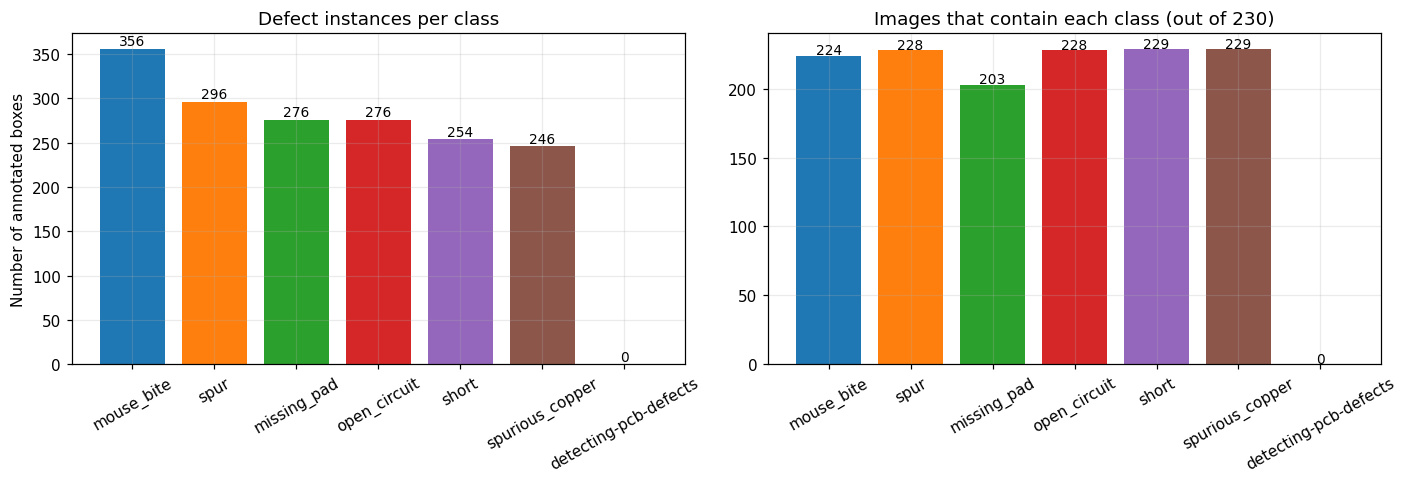

Largest class : mouse_bite (356.0)
Smallest class: detecting-pcb-defects (0.0)
Imbalance ratio (max/min) = inf | coefficient of variation = 0.47
Verdict: SEVERELY imbalanced


In [42]:
per_class["instances"] = pd.to_numeric(
    per_class["instances"], errors="coerce"
).fillna(0)

per_class["images_with_class"] = pd.to_numeric(
    per_class["images_with_class"], errors="coerce"
).fillna(0)

counts = per_class["instances"]
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

order = counts.sort_values(ascending=False)

bars = ax[0].bar(
    order.index, order.values,
    color=plt.cm.tab10.colors[:len(order)]
)
ax[0].set_title("Defect instances per class")
ax[0].set_ylabel("Number of annotated boxes")
ax[0].tick_params(axis="x", rotation=30)

for b in bars:
    ax[0].text(
        b.get_x() + b.get_width()/2,
        b.get_height() + 4,
        int(b.get_height()),
        ha="center", fontsize=9
    )

img_cnt = per_class["images_with_class"].reindex(order.index)

bars2 = ax[1].bar(
    img_cnt.index, img_cnt.values,
    color=plt.cm.tab10.colors[:len(order)]
)
ax[1].set_title(
    "Images that contain each class (out of %d)" % len(imgs)
)
ax[1].tick_params(axis="x", rotation=30)

for b in bars2:
    ax[1].text(
        b.get_x() + b.get_width()/2,
        b.get_height() + 1,
        int(b.get_height()),
        ha="center", fontsize=9
    )

plt.tight_layout()
plt.show()

# Imbalance analysis
if counts.empty or counts.max() == 0:
    print("No valid defect-instance counts found. Check the annotations.")
else:
    ratio = (
        counts.max() / counts.min()
        if counts.min() > 0 else float("inf")
    )
    gini_like = counts.std() / counts.mean()

    if ratio < 1.5:
        verdict = "MILDLY imbalanced / close to balanced"
    elif ratio < 3:
        verdict = "MODERATELY imbalanced"
    else:
        verdict = "SEVERELY imbalanced"

    print(f"Largest class : {counts.idxmax()} ({counts.max()})")
    print(f"Smallest class: {counts.idxmin()} ({counts.min()})")
    print(
        f"Imbalance ratio (max/min) = {ratio:.2f}"
        f" | coefficient of variation = {gini_like:.2f}"
    )
    print("Verdict:", verdict)

## B2. Sample images – 5 examples per class
Whole scans are 2–30 MP and a defect is tiny, so each tile below is a **crop around one annotated defect** (with surrounding context) and the red box marks the labelled region.

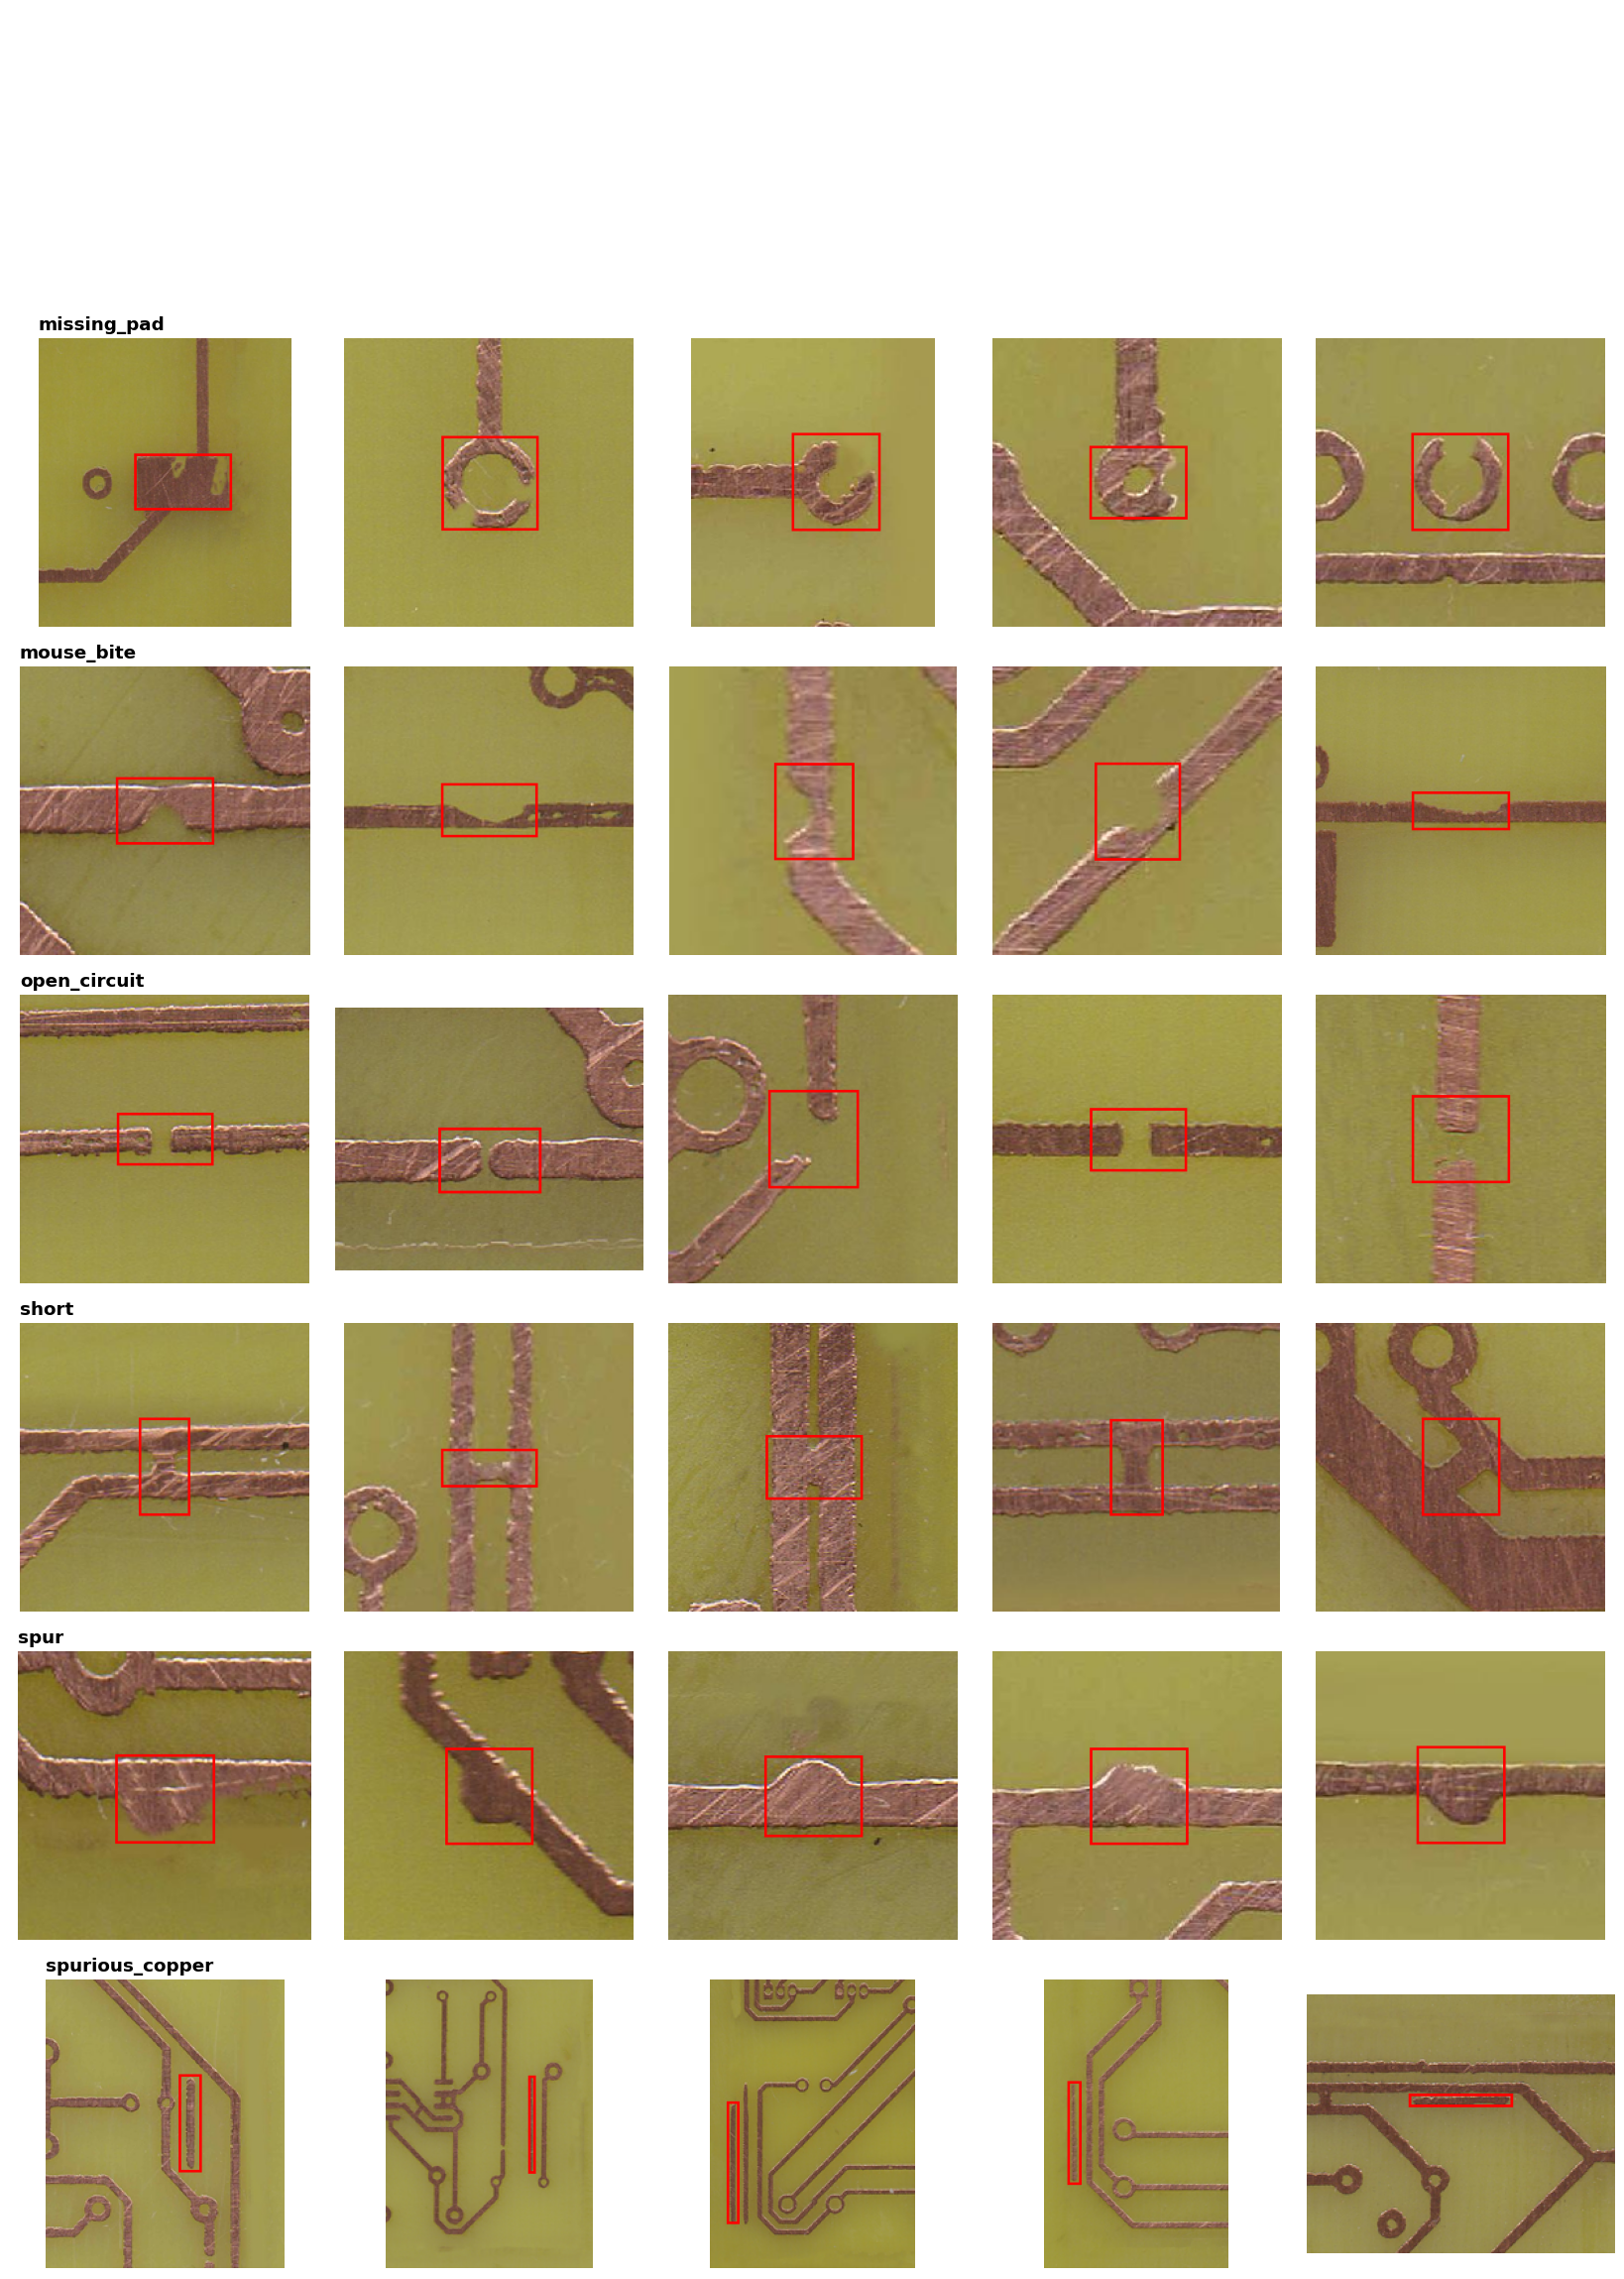

In [43]:
def crop_with_context(path, x, y, w, h, ctx=2.0, min_side=120, out=224):
    with Image.open(path) as I:
        I = I.convert("RGB")
        cx, cy = x + w/2, y + h/2
        side = max(max(w, h) * (1 + ctx), min_side)
        x0, y0 = int(max(cx - side/2, 0)), int(max(cy - side/2, 0))
        x1, y1 = int(min(cx + side/2, I.width)), int(min(cy + side/2, I.height))
        crop = I.crop((x0, y0, x1, y1))
        sc = out / max(crop.size)
        crop = crop.resize((max(1, int(crop.width*sc)), max(1, int(crop.height*sc))), Image.LANCZOS)
        d = ImageDraw.Draw(crop)
        d.rectangle([(x-x0)*sc, (y-y0)*sc, (x+w-x0)*sc, (y+h-y0)*sc], outline=(255, 0, 0), width=2)
    return crop

N_PER_CLASS = 5
fig, axes = plt.subplots(len(CLASSES), N_PER_CLASS, figsize=(3*N_PER_CLASS, 3*len(CLASSES)))
rng = np.random.RandomState(7)
for r, c in enumerate(CLASSES):
    sub = ann[ann["class"] == c]
    # prefer different images for variety
    picks = sub.drop_duplicates("image_id")
    picks = picks.sample(min(N_PER_CLASS, len(picks)), random_state=rng)
    for k in range(N_PER_CLASS):
        a = axes[r, k]; a.axis("off")
        if k < len(picks):
            row = picks.iloc[k]
            a.imshow(crop_with_context(row["path"], row["x"], row["y"], row["w"], row["h"]))
            if k == 0:
                a.set_title(c, loc="left", fontsize=12, fontweight="bold")
plt.tight_layout(); plt.show()

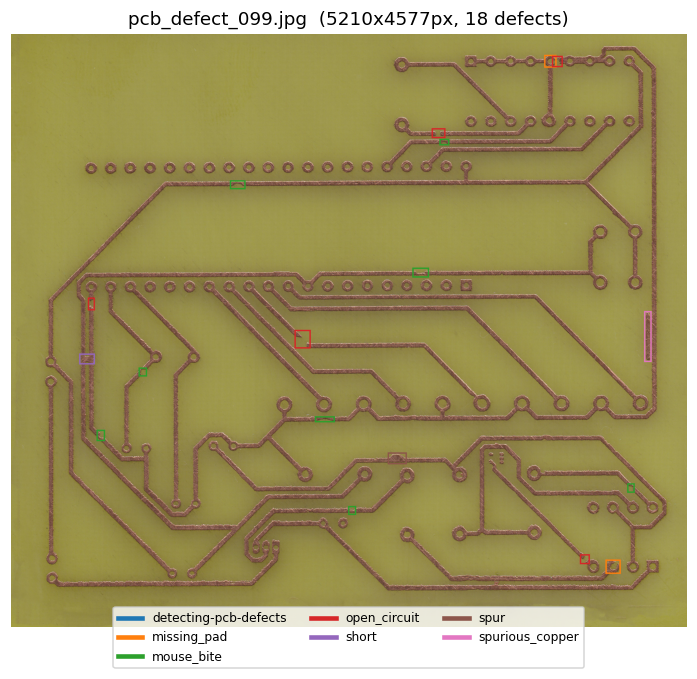

In [44]:
# one full board with all its labelled defects, to show global layout and context
sample_img = ann.groupby("image_id").size().sort_values(ascending=False).index[0]
row0 = imgs[imgs.image_id == sample_img].iloc[0]
with Image.open(row0["path"]) as I:
    I = I.convert("RGB"); sc = 1400 / max(I.size)
    small = I.resize((int(I.width*sc), int(I.height*sc)))
d = ImageDraw.Draw(small)
cmap = {c: tuple(int(255*v) for v in plt.cm.tab10.colors[i][:3]) for i, c in enumerate(CLASSES)}
for _, a in ann[ann.image_id == sample_img].iterrows():
    d.rectangle([a.x*sc, a.y*sc, (a.x+a.w)*sc, (a.y+a.h)*sc], outline=cmap[a["class"]], width=3)
plt.figure(figsize=(9, 7)); plt.imshow(small); plt.axis("off")
plt.title(f"{row0['file']}  ({row0.width}x{row0.height}px, {(ann.image_id==sample_img).sum()} defects)")
handles = [plt.Line2D([0], [0], color=np.array(v)/255, lw=3, label=k) for k, v in cmap.items()]
plt.legend(handles=handles, loc="lower center", ncol=3, fontsize=8, bbox_to_anchor=(0.5, -0.08)); plt.show()

## B3. Further EDA – what will affect the model
Defect size, number of defects per image, image-size variation, and a simple image-quality (sharpness / brightness) check.

/tmp/ipykernel_4727/1926743506.py:5: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax[0, 0].boxplot(data, labels=CLASSES, showfliers=True)
/tmp/ipykernel_4727/1926743506.py:20: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax[1, 1].boxplot(ar, labels=CLASSES); ax[1, 1].set_yscale("log")


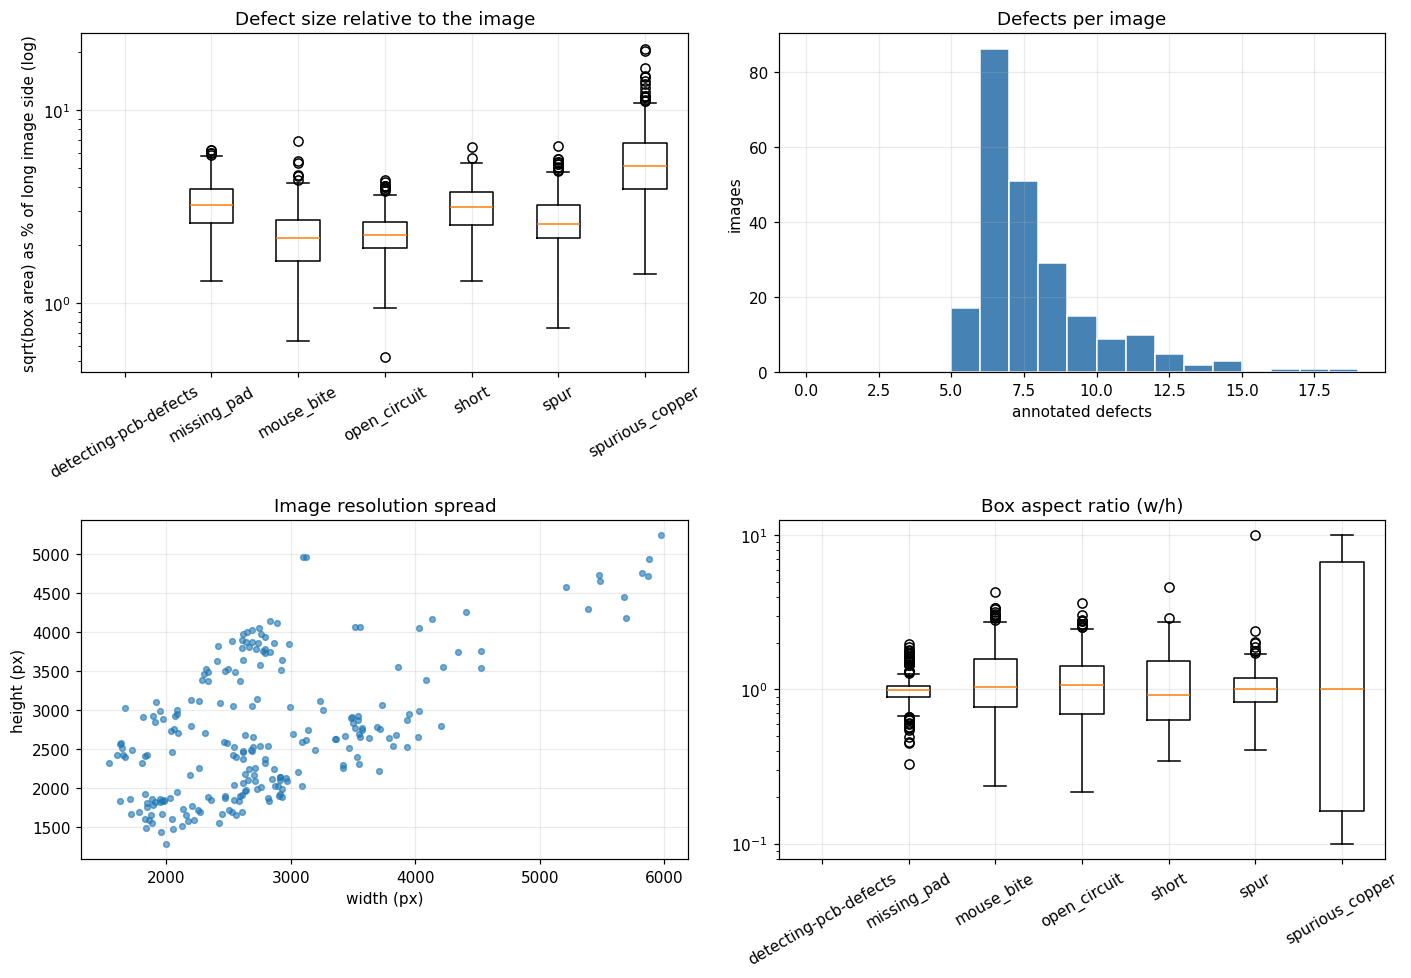

Median defect box: 82 x 83 px
Median defect side = 2.76% of the image's long side; 19.2% of defects are smaller than 2% of it.


In [45]:
fig, ax = plt.subplots(2, 2, figsize=(13, 9))

# (a) box size relative to the image
data = [ann.loc[ann["class"] == c, "rel_size"].values * 100 for c in CLASSES]
ax[0, 0].boxplot(data, labels=CLASSES, showfliers=True)
ax[0, 0].set_yscale("log"); ax[0, 0].set_ylabel("sqrt(box area) as % of long image side (log)")
ax[0, 0].set_title("Defect size relative to the image"); ax[0, 0].tick_params(axis="x", rotation=30)

# (b) defects per image
per_img = ann.groupby("image_id").size().reindex(imgs.image_id).fillna(0)
ax[0, 1].hist(per_img, bins=range(0, int(per_img.max())+2), color="steelblue", edgecolor="white")
ax[0, 1].set_title("Defects per image"); ax[0, 1].set_xlabel("annotated defects"); ax[0, 1].set_ylabel("images")

# (c) image sizes
ax[1, 0].scatter(imgs.width, imgs.height, s=14, alpha=.6)
ax[1, 0].set_xlabel("width (px)"); ax[1, 0].set_ylabel("height (px)"); ax[1, 0].set_title("Image resolution spread")

# (d) box aspect ratio per class
ar = [(ann.loc[ann["class"] == c, "w"] / ann.loc[ann["class"] == c, "h"]).clip(0.1, 10).values for c in CLASSES]
ax[1, 1].boxplot(ar, labels=CLASSES); ax[1, 1].set_yscale("log")
ax[1, 1].set_title("Box aspect ratio (w/h)"); ax[1, 1].tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

small_share = (ann["rel_size"] < 0.02).mean() * 100
print(f"Median defect box: {ann.w.median():.0f} x {ann.h.median():.0f} px")
print(f"Median defect side = {ann.rel_size.median()*100:.2f}% of the image's long side; "
      f"{small_share:.1f}% of defects are smaller than 2% of it.")

,mean,std,min,50%,max
image_id,114.50,66.54,0.00,114.50,229.00
sharpness,251.10,113.47,66.57,262.75,511.51
brightness,133.65,5.93,115.77,134.14,147.66
contrast,15.39,2.66,10.75,15.17,25.26
R,150.61,5.69,132.13,150.92,164.56
G,136.81,6.49,118.67,137.61,151.70
B,72.95,6.49,57.25,73.30,86.35


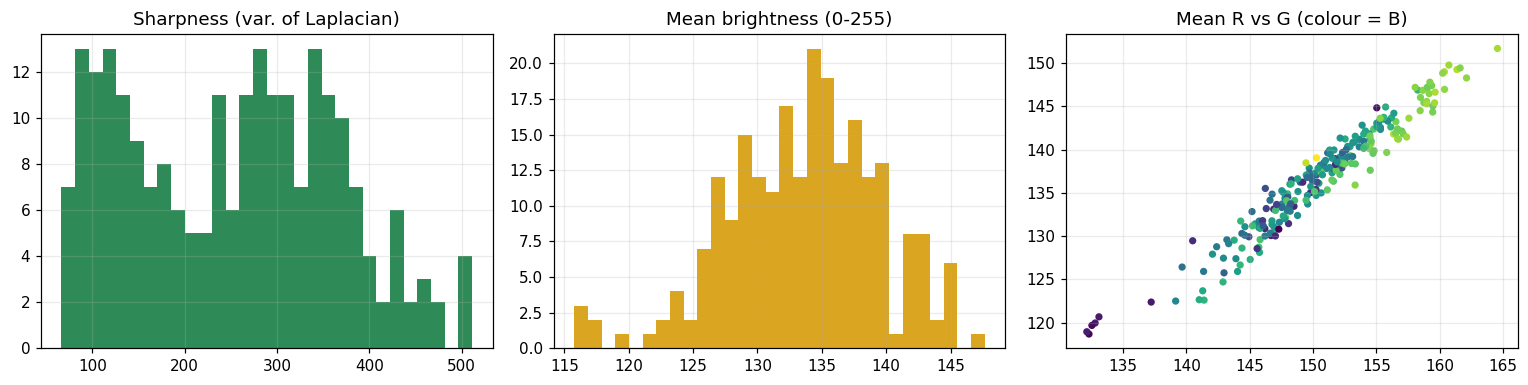

Brightness variation across images (CV) = 0.04; sharpness variation (CV) = 0.45


In [46]:
# ---- simple quality statistics on a downscaled copy: sharpness (variance of Laplacian), brightness, colour ----
stats = []
for _, r in imgs.iterrows():
    with Image.open(r["path"]) as I:
        I.draft("RGB", (1200, 1200))             # fast JPEG downscale
        I = I.convert("RGB")
        I.thumbnail((1024, 1024))
        a = np.asarray(I)
    g = cv2.cvtColor(a, cv2.COLOR_RGB2GRAY)
    stats.append(dict(image_id=r["image_id"], sharpness=cv2.Laplacian(g, cv2.CV_64F).var(),
                      brightness=g.mean(), contrast=g.std(), R=a[..., 0].mean(), G=a[..., 1].mean(), B=a[..., 2].mean()))
qs = pd.DataFrame(stats)
display(qs.describe().round(2).T[["mean", "std", "min", "50%", "max"]])

fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
ax[0].hist(qs.sharpness, bins=30, color="seagreen"); ax[0].set_title("Sharpness (var. of Laplacian)")
ax[1].hist(qs.brightness, bins=30, color="goldenrod"); ax[1].set_title("Mean brightness (0-255)")
ax[2].scatter(qs.R, qs.G, c=qs.B, cmap="viridis", s=14); ax[2].set_title("Mean R vs G (colour = B)")
plt.tight_layout(); plt.show()

cv_b = qs.brightness.std() / qs.brightness.mean()
cv_s = qs.sharpness.std() / qs.sharpness.mean()
print(f"Brightness variation across images (CV) = {cv_b:.2f}; sharpness variation (CV) = {cv_s:.2f}")

Classes with no valid box measurements: ['detecting-pcb-defects']


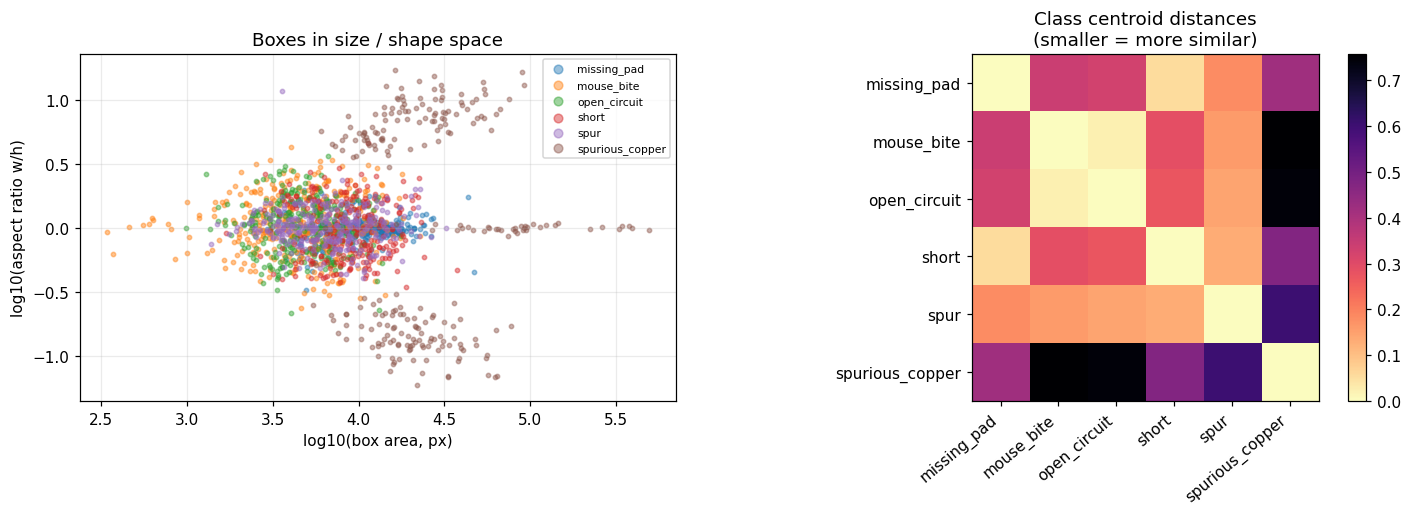

Most similar class pairs by box size/shape:
  mouse_bite       vs open_circuit     distance = 0.02
  missing_pad      vs short            distance = 0.05
  short            vs spur             distance = 0.13


In [47]:

# ---- class similarity: box size / shape ----

# Keep only valid annotations
feat = ann.copy()
feat = feat[
    feat["area_px"].gt(0)
    & feat["w"].gt(0)
    & feat["h"].gt(0)
].copy()

feat["log_area"] = np.log10(feat["area_px"])
feat["log_ar"] = np.log10((feat["w"] / feat["h"]).clip(0.05, 20))

# Calculate class averages
cen = feat.groupby("class")[["log_area", "log_ar"]].mean()
cen = cen.reindex(CLASSES)

# Identify classes without valid measurements
missing = cen[cen.isna().any(axis=1)].index.tolist()
if missing:
    print("Classes with no valid box measurements:", missing)

# Calculate distances only for classes with valid measurements
valid_cen = cen.dropna()
D = pd.DataFrame(
    np.linalg.norm(
        valid_cen.values[:, None] - valid_cen.values[None, :],
        axis=-1
    ),
    index=valid_cen.index,
    columns=valid_cen.index
)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))

for c in valid_cen.index:
    s = feat[feat["class"] == c]
    ax[0].scatter(
        s["log_area"], s["log_ar"],
        s=8, alpha=0.45, label=c
    )

ax[0].set_xlabel("log10(box area, px)")
ax[0].set_ylabel("log10(aspect ratio w/h)")
ax[0].set_title("Boxes in size / shape space")
ax[0].legend(fontsize=7, markerscale=2)

im = ax[1].imshow(D.values, cmap="magma_r")
ax[1].set_xticks(range(len(D.columns)))
ax[1].set_yticks(range(len(D.index)))
ax[1].set_xticklabels(D.columns, rotation=40, ha="right")
ax[1].set_yticklabels(D.index)
ax[1].set_title("Class centroid distances\n(smaller = more similar)")
ax[1].grid(False)

plt.colorbar(im, ax=ax[1], fraction=0.046)
plt.tight_layout()
plt.show()

# Find the three most similar pairs
pairs = [
    (D.index[i], D.columns[j], D.iloc[i, j])
    for i in range(len(D)) for j in range(i + 1, len(D))
]
pairs.sort(key=lambda t: t[2])

print("Most similar class pairs by box size/shape:")
for a_, b_, v in pairs[:3]:
    print(f"  {a_:16s} vs {b_:16s} distance = {v:.2f}")


## B4. Written findings

The numeric statements below come from the cells above; a live summary is printed in the next cell so the text always matches the data.

**1. Class imbalance.** The six classes are **close to balanced** in Version 1 (largest `mouse_bite` = 356 vs smallest `spurious_copper` = 246, ratio ≈ 1.45).
There is no rare class, but `mouse_bite` is over-represented by ~40 % over the smallest class. The bigger imbalance is *foreground vs background*: defects are tiny regions on very large boards,
so almost all pixels are "no defect".
→ **Handling:** stratified split **by board image** (not by box) so all six classes appear in train/val/test; report **per-class** precision/recall/F1 and mAP, not only overall accuracy;
use class-weighted or focal loss only if per-class recall turns out uneven; hard-negative / background tiles during training.

**2. Very small objects and huge, variable image sizes.** Images range from under 1 MP to about 30 MP and the median defect is only a small fraction of the image width.
Shrinking a whole 6000 × 4000 board to 640 px would erase many defects.
→ **Preprocessing:** tile each board into overlapping crops (e.g. 640 × 640, ~20 % overlap) at native or mildly reduced resolution, keep boxes that are ≥ ~50 % inside the tile,
train on tiles and merge detections with NMS at test time; normalise with ImageNet statistics; keep **tiles of the same board in the same split** to avoid leakage.

**3. Noise and acquisition effects.** Scans come from one flatbed scanner with automatic exposure and no correction, so brightness/sharpness vary between boards (see B3), and etched copper edges are rough rather than smooth.
The Bangladesh test boards will be photographed with a different device, lighting and board appearance, so a **domain shift** is expected.
→ **Augmentation:** brightness/contrast/gamma and hue-saturation jitter, Gaussian blur and sensor noise, small scale and rotation jitter, JPEG compression. These imitate camera differences without altering defect geometry.

**4. Class similarity.** Several classes are visually close because they are all small copper anomalies: `spur` vs `spurious_copper` (extra copper attached vs detached), `short` vs `spurious_copper` (extra copper bridging vs sitting alone),
and `open_circuit` vs `mouse_bite` (missing copper on a trace, small notch vs full break). The size/shape plot in B3 shows how much their boxes overlap.
→ **Handling:** keep enough spatial context around each defect (tile rather than tight crop), examine the confusion matrix for these pairs, and use Grad-CAM to check that the model looks at the defect and not at the board layout.

**5. Orientation.** Defects occur at arbitrary angles and boards have no canonical orientation, so **horizontal/vertical flips and 90° rotations are label-safe**. Heavy geometric warping, random erasing or cut-out
are avoided because they can delete or distort a tiny defect.

**6. Small dataset (230 boards).** Training from scratch is risky → use a pretrained lightweight backbone (e.g. MobileNetV3 / EfficientNet-Lite / a nano YOLO-style detector) with transfer learning, early stopping, and a held-out validation set.
**What we will NOT do:** paste synthetic defects or train on the Bangladesh test boards.

In [48]:
print("=== Auto-generated findings from the data ===")
print(f"* {len(imgs)} images, {len(ann)} boxes, {len(CLASSES)} classes; {ann.image_id.nunique()} images carry at least one box.")
print(f"* Imbalance ratio {ratio:.2f} ({verdict}); {counts.idxmax()} is largest, {counts.idxmin()} smallest.")
print(f"* Image sizes: {imgs.width.min()}x{imgs.height.min()} to {imgs.width.max()}x{imgs.height.max()} px "
      f"({imgs.megapixels.min():.1f}-{imgs.megapixels.max():.1f} MP) -> {imgs[['width','height']].drop_duplicates().shape[0]} distinct sizes.")
print(f"* Median defect side = {ann.rel_size.median()*100:.2f}% of the long image side -> tiling needed.")
print(f"* Brightness CV = {cv_b:.2f}, sharpness CV = {cv_s:.2f} -> photometric augmentation justified.")
print(f"* Closest class pair by box size/shape: {pairs[0][0]} vs {pairs[0][1]}.")

=== Auto-generated findings from the data ===
* 230 images, 1704 boxes, 7 classes; 230 images carry at least one box.
* Imbalance ratio inf (SEVERELY imbalanced); mouse_bite is largest, detecting-pcb-defects smallest.
* Image sizes: 1540x1285 to 5971x5236 px (2.6-31.3 MP) -> 230 distinct sizes.
* Median defect side = 2.76% of the long image side -> tiling needed.
* Brightness CV = 0.04, sharpness CV = 0.45 -> photometric augmentation justified.
* Closest class pair by box size/shape: mouse_bite vs open_circuit.


---
# C. Related work summary
No peer-reviewed model paper using **this exact dataset** was found yet (it was released in Aug 2025), so the table covers the dataset paper itself plus the closest, most cited PCB-defect papers. Results are copied from the papers as reported; they are **not directly comparable** because datasets, splits and metrics differ (DeepPCB and PKU-Market-PCB contain digitally inserted defects, unlike our etched-defect data).

| # | Paper (author, year) | Dataset used | Model(s) | Approach (preprocessing, augmentation, transfer learning, attention, etc.) | Result (accuracy / F1 / AUC) | Reference link |
|---|---|---|---|---|---|---|
| 1 | Tang, He, Huang, Yang, 2019 – *Online PCB Defect Detector on a New PCB Defect Dataset* | DeepPCB (1,500 template/test image pairs, 640×640, 6 classes) | Template-vs-test CNN with a *group pyramid pooling* (GPP) module on an SSD/FPN-style detector | Uses the defect-free template together with the tested image; GPP extracts multi-scale features that are merged by group; max pooling outperformed average pooling. No transfer learning described. | Ablation: precision 98.2, recall 98.1, F-mean **98.2** | https://arxiv.org/abs/1902.06197 |
| 2 | He, Tang, Mehrkanoon, Huang, Yang, 2020 – *A Real-time PCB Defect Detector Based on Supervised and Semi-supervised Learning* (ESANN) | DeepPCB | Same GPP-based detector plus a mean-teacher semi-supervised variant | Exponential-moving-average teacher model uses unlabelled images via a consistency loss; designed for real-time inference | **98.6 % mAP @ 62 FPS** | https://www.esann.org/sites/default/files/proceedings/2020/ES2020-33.pdf |
| 3 | Bhattacharya & Cloutier, 2022 – *End-to-end deep learning framework for PCB manufacturing defect classification* (Sci. Rep. 12:12559) | PKU-Market-PCB (Huang & Wei 2019; 6 defect types) | YOLOv5 family (s/m/l) and the authors' proposed single-step framework | Compares against YOLOv5 variants; framework combines data augmentation, multilevel feature fusion and transformer components; works on low-resolution images for speed | **98.1 % mAP@0.5** on test samples | https://doi.org/10.1038/s41598-022-16302-3 |
| 4 | Rashid, Ullah, Isfara, Ahmed, Mian, Shalehin, 2025 – *PCB-defect: An annotated dataset for surface defect detection in printed circuit boards* (Data in Brief 64:112296) | PCB-Defect (our dataset: 230 etched boards, 1,704 boxes, 6 classes) | None – dataset paper (no baseline model reported) | Describes physical etching, scanning, Roboflow annotation with two validation rounds, COCO JSON format; lists limitations | N/A (no model results published) | https://doi.org/10.1016/j.dib.2025.112296 |

**Take-aways for PCB-LiteX**
* The published high scores (98 %+) come from datasets with *inserted* defects and tiled 640×640 images; our etched, full-resolution data with only 230 boards is likely harder, so we should expect lower numbers and must not compare directly.
* Multi-scale feature fusion (GPP / FPN) and light-weight YOLO-style detectors are the common route to small-defect accuracy at real-time speed – a good fit for our lightweight goal.
* None of these papers evaluates **cross-dataset generalisation** or uses **explainability** (Grad-CAM); that is the gap PCB-LiteX targets.

In [49]:
related = pd.DataFrame([
    [1, "Tang et al., 2019", "DeepPCB", "SSD/FPN-style CNN + group pyramid pooling", "Template + test pair; multi-scale grouped features", "P 98.2 / R 98.1 / F 98.2", "https://arxiv.org/abs/1902.06197"],
    [2, "He et al., 2020 (ESANN)", "DeepPCB", "GPP detector + mean-teacher", "Semi-supervised learning with unlabelled images", "mAP 98.6 @ 62 FPS", "https://www.esann.org/sites/default/files/proceedings/2020/ES2020-33.pdf"],
    [3, "Bhattacharya & Cloutier, 2022", "PKU-Market-PCB", "YOLOv5 variants + proposed framework", "Augmentation, multilevel feature fusion, transformer, low-res input", "mAP@0.5 98.1", "https://doi.org/10.1038/s41598-022-16302-3"],
    [4, "Rashid et al., 2025", "PCB-Defect (ours)", "- (dataset paper)", "Physical etching, Roboflow annotation, COCO JSON", "N/A", "https://doi.org/10.1016/j.dib.2025.112296"],
], columns=["#", "Paper (author, year)", "Dataset", "Model(s)", "Approach", "Result", "Reference link"])
display(related.style.hide(axis="index").set_properties(**{"text-align": "left", "white-space": "pre-wrap"}))

#,"Paper (author, year)",Dataset,Model(s),Approach,Result,Reference link
1,"Tang et al., 2019",DeepPCB,SSD/FPN-style CNN + group pyramid pooling,Template + test pair; multi-scale grouped features,P 98.2 / R 98.1 / F 98.2,https://arxiv.org/abs/1902.06197
2,"He et al., 2020 (ESANN)",DeepPCB,GPP detector + mean-teacher,Semi-supervised learning with unlabelled images,mAP 98.6 @ 62 FPS,https://www.esann.org/sites/default/files/proceedings/2020/ES2020-33.pdf
3,"Bhattacharya & Cloutier, 2022",PKU-Market-PCB,YOLOv5 variants + proposed framework,"Augmentation, multilevel feature fusion, transformer, low-res input",mAP@0.5 98.1,https://doi.org/10.1038/s41598-022-16302-3
4,"Rashid et al., 2025",PCB-Defect (ours),- (dataset paper),"Physical etching, Roboflow annotation, COCO JSON",N/A,https://doi.org/10.1016/j.dib.2025.112296


---
# Summary
* **Dataset:** PCB-Defect (Mendeley Data, CC BY 4.0, 2025), 230 single-layer boards with physically etched defects, 6-class object detection, COCO JSON boxes, JPEG RGB.
* **EDA:** classes are nearly balanced; defects are tiny on very large, variable-resolution scans; photometric variation exists across boards; several classes look alike.
* **Plan:** tile images, split by board, use label-safe geometric + photometric augmentation, a pretrained lightweight backbone, per-class metrics and Grad-CAM, and keep the Bangladesh boards strictly for testing.